# Notebook 08 — Caso de Estudio: Sensor Virtual del Número Kappa (Digestor Kamyr)

## Módulo 5 — Reto Práctico Independiente

En una planta de celulosa Kraft, el **Número Kappa (`Y-Kappa`)** mide el contenido residual de lignina de la pulpa a la salida del digestor continuo Kamyr.
- La titulación en laboratorio tiene alto retraso de muestreo y variabilidad operativa.
- Especificación objetivo típica: **`18.0 – 24.0` Kappa** (valor medio histórico `~20.6`).

Tu misión es diseñar y validar un sensor virtual completo sobre `kamyr_digester_case_study.csv` (`301` registros horarios × `23` columnas), resolviendo desafíos reales de planta:
1. Nombres de columna con espacios finales (ej. `'ChipLevel4 '`, `'WhiteFlow-4 '`).
2. **46.8% de valores faltantes** en dos titulaciones auxiliares (`AAWhiteSt-4` y `SulphidityL-4`).
3. Tiempo de residencia de astillas (~1–3 h): ingeniería de variables (`liquor_to_chip`, `heater_deltaT`, rezagos).
4. Comparativa **PLS vs Ridge vs LightGBM**, cuantiles **P10–P90** y explicabilidad **SHAP** para responder la evaluación del Módulo 5.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cross_decomposition import PLSRegression
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import lightgbm as lgb
import shap

plt.style.use("seaborn-v0_8-whitegrid")
COLORS = ["#007297", "#8EC14B", "#E8820C", "#C0392B", "#0D202B"]

KAMYR_URL = "https://d29ikw7e1z6k4e.cloudfront.net/curso_sensor/kamyr_digester_case_study.csv"
df = pd.read_csv(KAMYR_URL)
# Paso crítico de higiene: limpiar espacios en los nombres de columnas
df.columns = df.columns.str.strip()

print(f"Dataset Kamyr cargado: {df.shape[0]} filas x {df.shape[1]} columnas")
df.head(3)

Dataset Kamyr cargado: 301 filas x 23 columnas


,Observation,Y-Kappa,ChipRate,BF-CMratio,BlowFlow,ChipLevel4,T-upperExt-2,T-lowerExt-2,UCZAA,WhiteFlow-4,...,SteamFlow-4,Lower-HeatT-3,Upper-HeatT-3,ChipMass-4,WeakLiquorF,BlackFlow-2,WeakWashF,SteamHeatF-3,T-Top-Chips-4,SulphidityL-4
0,31-00:00,23.10,16.520,121.717,1177.607,169.805,358.282,329.545,1.443,599.253,...,67.122,329.432,303.099,175.964,1127.197,1319.039,257.325,54.612,252.077,NaN
1,31-01:00,27.60,16.810,79.022,1328.360,341.327,351.050,329.067,1.549,537.201,...,60.012,330.823,304.879,163.202,665.975,1297.317,241.182,46.603,251.406,29.11
2,31-02:00,23.19,16.709,79.562,1329.407,239.161,350.022,329.260,1.600,549.611,...,61.304,329.140,303.383,164.013,677.534,1327.072,237.272,51.795,251.335,NaN


=== Columnas con datos faltantes (%) ===
SulphidityL-4     46.8
AAWhiteSt-4       46.8
UCZAA              8.0
BF-CMratio         4.7
BlowFlow           4.3
ChipRate           1.3
Lower-HeatT-3      0.3
T-Top-Chips-4      0.3
SteamHeatF-3       0.3
WeakWashF          0.3
BlackFlow-2        0.3
WeakLiquorF        0.3
ChipMass-4         0.3
Upper-HeatT-3      0.3
AA-Wood-4          0.3
SteamFlow-4        0.3
ChipMoisture-4     0.3
WhiteFlow-4        0.3
T-lowerExt-2       0.3
T-upperExt-2       0.3
ChipLevel4         0.3
dtype: float64


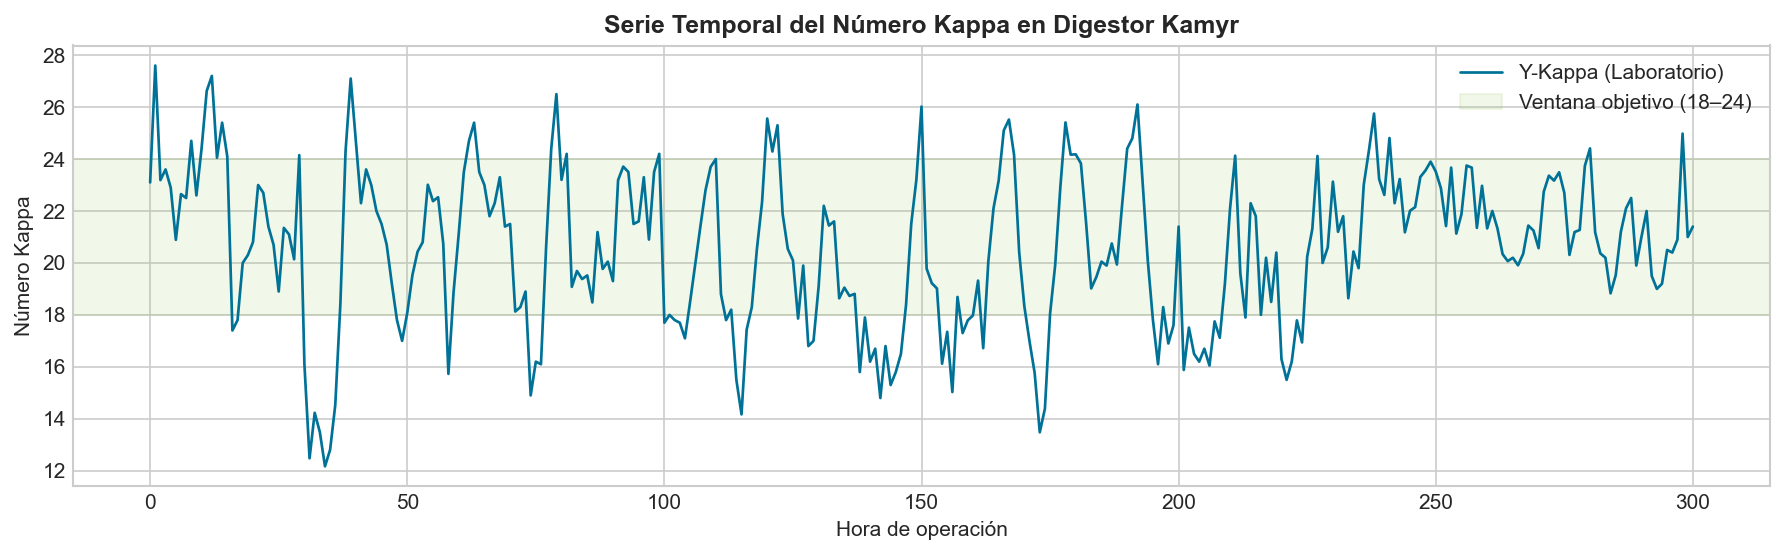

In [2]:
# Diagnóstico de faltantes y serie temporal de Y-Kappa
missing_pct = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
print("=== Columnas con datos faltantes (%) ===")
print(missing_pct[missing_pct > 0])

fig, ax = plt.subplots(figsize=(12, 3.8), dpi=150)
ax.plot(df["Y-Kappa"], color=COLORS[0], linewidth=1.3, label="Y-Kappa (Laboratorio)")
ax.axhspan(18, 24, color=COLORS[1], alpha=0.12, label="Ventana objetivo (18–24)")
ax.set_title("Serie Temporal del Número Kappa en Digestor Kamyr", fontsize=12, fontweight="bold")
ax.set_xlabel("Hora de operación")
ax.set_ylabel("Número Kappa")
ax.legend()
plt.tight_layout()
plt.show()

### Reto 1: Limpieza y Manejo de Faltantes Masivos (`>30%`)
`AAWhiteSt-4` y `SulphidityL-4` faltan casi la mitad del tiempo (`46.8%`). Imputarlas con la mediana introduciría un sesgo constante artificial.
**Tu tarea:** elimínalas del set de entrada, define la partición cronológica **70% Train / 15% Val / 15% Test**, recorta outliers (`P1–P99`) e imputa el resto de sensores usando **solo Train**.

In [3]:
# TODO 1: Completa la limpieza sin data leakage
drop_cols = [c for c in df.columns if df[c].isna().mean() > 0.30]
print("Columnas descartadas (>30% nulos):", drop_cols)
df_clean = df.drop(columns=drop_cols).copy()

n = len(df_clean)
n_tr, n_va = int(n * 0.70), int(n * 0.85)
num_cols = [c for c in df_clean.select_dtypes(include=[np.number]).columns if c != "Y-Kappa"]

for col in num_cols:
    p01, p99 = df_clean.loc[:n_tr-1, col].quantile(0.01), df_clean.loc[:n_tr-1, col].quantile(0.99)
    df_clean[col] = df_clean[col].clip(p01, p99).fillna(df_clean.loc[:n_tr-1, col].median())

print("Nulos restantes tras limpieza:", int(df_clean.isna().sum().sum()))

Columnas descartadas (>30% nulos): ['AAWhiteSt-4', 'SulphidityL-4']
Nulos restantes tras limpieza: 0


### Reto 2: Ingeniería de Variables del Digestor + Benchmark de Modelos + SHAP
Construye variables físicas clave del proceso Kraft y compara **PLS (3 comp.)**, **Ridge** y **LightGBM** en Validación.

In [4]:
# TODO 2: Ejecuta o amplía estas variables físicas y evalúa los modelos
df_clean["heater_deltaT"]  = df_clean["Lower-HeatT-3"] - df_clean["Upper-HeatT-3"]
df_clean["ext_temp_diff"]  = df_clean["T-upperExt-2"] - df_clean["T-lowerExt-2"]
df_clean["liquor_to_chip"] = df_clean["WhiteFlow-4"] / (df_clean["ChipRate"] + 1e-6)
df_clean["T_upperExt_lag1"] = df_clean["T-upperExt-2"].shift(1)
df_clean["SteamFlow_lag1"]  = df_clean["SteamFlow-4"].shift(1)

df_clean["split"] = np.where(df_clean.index < n_tr, "train", np.where(df_clean.index < n_va, "val", "test"))
df_ready = df_clean.dropna().reset_index(drop=True)
f_cols = [c for c in df_ready.columns if c not in ["Observation", "Y-Kappa", "split"]]

# Completa la comparación de modelos aquí (PLS, Ridge, LightGBM) y calcula SHAP sobre Validación:
# Pista: ¿aparecen 'liquor_to_chip', 'T_upperExt_lag1' y 'SteamFlow_lag1' entre los top 5 drivers?
print(f"Dataset Kamyr listo para modelar: {df_ready.shape[0]} filas x {len(f_cols)} features")

Dataset Kamyr listo para modelar: 300 filas x 24 features


### Checkpoint Final (Para Responder el Quiz del Módulo 5)
Asegúrate de verificar en tu ejecución:
1. ¿Qué porcentaje exacto de nulos presentaban `AAWhiteSt-4` y `SulphidityL-4`?
2. ¿Qué ocurre al comparar el RMSE de Validación entre **PLS**, **Ridge** y **LightGBM**?
3. ¿Cuáles son los principales impulsores físicos de `Y-Kappa` revelados por **SHAP**?